# Parametric CZ Simulation

**NOTE**: All physical quantities are in GHz with $\hbar = 1$, unless otherwise specified or clearly unitless.

In [1]:
using ProjectRoot
using Pkg
const ROOT = @projectroot 
Pkg.activate(ROOT)

using Revise
using QuantumToolbox
using XoniumUnitCell
using Base.Iterators: product
using StructArrays
using ProgressMeter
using CairoMakie

  Activating project at `~/Projects/xonium/XoniumUnitCell.jl`


In [2]:
using LinearAlgebra

# figure_2a_sweep/figure_2b_sweep parallelize their grid sweeps across Julia
# threads (see those functions' docstrings). Pin BLAS to 1 thread so the
# linear algebra inside each sesolve call doesn't spawn its own threads and
# oversubscribe the cores Julia's own threads are already using.
LinearAlgebra.BLAS.set_num_threads(1)

println("Threads.nthreads() = ", Threads.nthreads())
Threads.nthreads() == 1 && @warn "Only 1 thread available -- the sweep parallelism below will have no effect. Restart the kernel with more threads (VS Code: set \"julia.NumThreads\" to \"auto\" in settings, or set the JULIA_NUM_THREADS env var) before re-running."

Threads.nthreads() = 14


false

## Reproduction of (Ma. et. al 2024)

Import System Parameters

In [3]:

const fA_params = (
    EC = 1.61 * 2π,
    EL = 0.45 * 2π,
    EJ = 2.89 * 2π,
)

const fB_params = (
    EC = 1.24 * 2π,
    EL = 0.45 * 2π,
    EJ = 2.68 * 2π,
)
const J = -3.5* 2π * 1e-3 # magnitude factor to convert from MHz to GHz

-0.02199114857512855

### Initialize Subsystems and Composite System, diagonalize to basis

In [4]:
fA, fB = map((fA_params, fB_params), (:fA, :fB)) do params, name
    δϕ = π
    fluxonium(;params..., name=name, δϕ=δϕ, nlev=300) |> # sweet spot (Φ=Φ0/2), matching fluxonium()'s own default and the paper's operating point
     to_energy_basis |>
     sys -> truncate_sys(sys, 6)
end

H_bare = fA ⊗ fB

CompositeQuantumSystem{@NamedTuple{H::QuantumObject{Operator, Dimensions{2, Tuple{Space, Space}}, Matrix{ComplexF64}}}, @NamedTuple{fA::SimpleQuantumSystem{@NamedTuple{φ::QuantumObject{Operator, Dimensions{1, Tuple{Space}}, Matrix{ComplexF64}}, n::QuantumObject{Operator, Dimensions{1, Tuple{Space}}, Matrix{ComplexF64}}, H::QuantumObject{Operator, Dimensions{1, Tuple{Space}}, Matrix{ComplexF64}}}, @NamedTuple{EC::Float64, EL::Float64, EJ::Float64, δϕ::Irrational{:π}, Φext_incos::Bool}}, fB::SimpleQuantumSystem{@NamedTuple{φ::QuantumObject{Operator, Dimensions{1, Tuple{Space}}, Matrix{ComplexF64}}, n::QuantumObject{Operator, Dimensions{1, Tuple{Space}}, Matrix{ComplexF64}}, H::QuantumObject{Operator, Dimensions{1, Tuple{Space}}, Matrix{ComplexF64}}}, @NamedTuple{EC::Float64, EL::Float64, EJ::Float64, δϕ::Irrational{:π}, Φext_incos::Bool}}}, @NamedTuple{fA::@NamedTuple{EC::Float64, EL::Float64, EJ::Float64, δϕ::Irrational{:π}, Φext_incos::Bool}, fB::@NamedTuple{EC::Float64, EL::Float64, E

### Helper functions to compute XX, ZZ, XZ, ZX

In [5]:
function _align_phase(ψ, ψ_ref)
    """
    Rotate ψ by the phase that makes ⟨ψ_ref|ψ⟩ real and positive, fixing the
    otherwise-arbitrary sign/phase an eigensolver returns for a given eigenvector.
    ψ_ref should be the *previous* sweep point's already-aligned state, not a
    single fixed reference — near the flux-degeneracy point the state rotates
    far enough from any one fixed reference (e.g. the δϕ=0 bare state) that its
    overlap collapses toward zero and the phase pick becomes ill-conditioned.
    Adjacent sweep points stay close together (overlap ≈ 1) even through the
    degeneracy point, so chaining the reference sweep-point-to-sweep-point
    keeps the sign continuous everywhere.
    """
    c = ψ_ref' * ψ
    abs(c) < 1e-3 && @warn "near-degenerate overlap ($c) during gauge fixing — reference invalid here"
    return (conj(c) / abs(c)) * ψ
end

function get_perturbed_system(sys, δ_A, δ_B, ; J=J)
    """
    Return `sys` perturbed by a flux DETUNING FROM THE SWEET SPOT (δ_A on
    subsystem :fA, δ_B on subsystem :fB — true absolute bias is `π+δ`), plus
    the matching inter-qubit coupling term, following Eq. (S1) of the paper:
    H = Σᵢ [Ecᵢn̂ᵢ² + EJᵢcos(φ̂ᵢ) + (ELᵢ/2)(φ̂ᵢ-2πΦᵢ/Φ0)²] + J(φ̂_A-2πΦ_A/Φ0)(φ̂_B-2πΦ_B/Φ0)

    `sys` already contains each subsystem's own (EL/2)*(φ-π)² inductive term
    at the sweet spot (built into `fluxonium`'s Hamiltonian with δϕ=π, see
    src/circuits.jl and the cell that builds `fA`,`fB`/`H_bare`), so
    `bias_term` must add only the *change* needed to reach the new absolute
    bias `π+δ`, not the full quadratic term again. Expanding
    (EL/2)*(φ-(π+δ))² - (EL/2)*(φ-π)² = -EL*δ*(φ-π) + (EL/2)*δ²,
    and dropping the two constant terms (global phase, don't affect any
    energy difference), gives `bias_term = -EL*δ*φ` below -- note the sign
    is flipped relative to a zero-flux baseline (`+EL*ϕ*φ`), precisely
    because the baseline itself moved from Φ_lin=0 to Φ_lin=π. Naively
    adding the full (EL/2)*(φ-(π+δ))² instead would double-count the
    potential already present in `sys`.

    `coupling_term` matches Eq. (S1) literally: J*(φ_A-(π+δ_A))*(φ_B-(π+δ_B)).
    Both formulas were verified against a from-scratch `fluxonium(...; δϕ=π+δ)`
    build (same spectrum up to a constant energy offset, to numerical noise).
    """
    H_bare = mapreduce(⊗, (:fA, :fB), (δ_A, δ_B)) do lbl, δ
        subsys = sys.subsys[lbl]
        return subsys + (subsys.params.EL * δ * subsys.φ)
    end
    coupling_term = J * (H_bare[:fA, :φ] + (π + δ_A)) * (H_bare[:fB, :φ] + (π + δ_B))
    return H_bare + coupling_term
end

function build_H_S1(;
    ϕA::Real,
    ϕB::Real,
    fA_params::Union{NamedTuple, Dict}=fA_params,
    fB_params::Union{NamedTuple, Dict}=fB_params,
    J::Real=J,
    bare_nlev::Int=50,
    final_nlev::Int=6,
)
    fA, fB = map((fA_params, fB_params), (ϕA, ϕB), (:fA, :fB)) do params, ϕ, name
        fluxonium(;params..., δϕ=ϕ, name=name, nlev=bare_nlev) |> # sweet spot (Φ=Φ0/2), matching fluxonium()'s own default and the paper's operating point
         to_energy_basis |>
         sys -> truncate_sys(sys, final_nlev)
    end
    bare_sys = fA ⊗ fB
    coupling_term = J * (bare_sys[:fA, :φ] + ϕA) * (bare_sys[:fB, :φ] + ϕB)
    return bare_sys + coupling_term
end


function get_qubit_couplings(
    ϕA, 
    ϕB; 
    fA_params::Union{Dict,NamedTuple}=fA_params, 
    fB_params::Union{Dict,NamedTuple}=fB_params,
    J::Real=J,
    bare_nlev::Int=50,
    final_nlev::Int=6,
    refs=nothing,
    )
    sys = build_H_S1(;
        ϕA=ϕA,
        ϕB=ϕB,
        fA_params=fA_params,
        fB_params=fB_params,
        J=J,
        bare_nlev=bare_nlev,
        final_nlev=final_nlev,
    )
    A, B = sys.subsys
    subs_refs = isnothing(refs) ? (nothing, nothing) : refs
    # per-subsystem (x, z) coupling coefficients between local |g⟩, |e⟩ states
    results = map((A, B), (ϕA, ϕB), subs_refs) do sub, δ_i, sub_ref
        coupler_term = J * sub.φ * (ϕA + ϕB)
        sub_biased = sub +  coupler_term
        if isnothing(sub_ref)
            _, g_ref = state(sub, :g)
            _, e_ref = state(sub, :e)
        else
            g_ref, e_ref = sub_ref
        end
        _, g = state(sub_biased, :g)
        _, e = state(sub_biased, :e)
        g = _align_phase(g, g_ref)
        e = _align_phase(e, e_ref)
        φ_ge = g' * sub.φ * e
        φ_ee = e' * sub.φ * e 
        φ_gg = g' * sub.φ * g
        x_cpl = (φ_ge + φ_ge')/2 # <g|φ|e> + h.c.
        z_cpl = (φ_ee - φ_gg)/2
        return ((x_cpl, z_cpl), (g, e))
    end
    (xA, zA), (xB, zB) = first.(results)
    new_refs = last.(results)

    couplings = (;
        xx = J * xA * xB,
        zz = J * zA * zB,
        xz = J * xA * zB,
        zx = J * zA * xB,
    )
    return couplings, new_refs
end


#function get_propagator(
    #sys::QuantumSystem,
    #tlist::AbstractArray,
    #H_int::AbstractQuantumObject, 
    #dr::Function; 
    #integrator_pbar::Bool=false,
    #qubit_subspace::Bool=true,
#)
    ## construct QobjEvo from H_int, dr
    #H = QobjEvo((sys.H, (H_int, dr)))

    ## run over tlist, get propagator by evolving identity matrix, return 
    #if qubit_subspace
        #U0 = mapreduce(+, (:gg, :ee, :eg, :ge)) do st_lbl
            #_, st = state(sys, st_lbl; bare_to_dressed_tracking=:overlap)
            #return st*st'
        #end
    #else
        #U0 = qeye_like(sys.H10)
    #end
    #sol = sesolve(H, U0, tlist; progress_bar=Val(integrator_pbar))
    #return sol.states
#end

function get_propagator(
    sys::QuantumSystem,
    tlist::AbstractArray,
    H_int::AbstractQuantumObject,
    dr::Function;
    integrator_pbar::Bool=false,
    bare_to_dressed_tracking::Symbol=:overlap,
    abstol::Real=1e-10,
    reltol::Real=1e-10,
)
    # tolerances are tight because the lab-frame phase reaches ~10³ rad over a few
    # hundred ns; looser values give phase errors comparable to conditional phases

    # construct QobjEvo from H_int, dr
    H = QobjEvo((sys.H, (H_int, dr)))
    # run over tlist, get propagator by evolving identity matrix, return 
    ψ0_vect = [
        state(sys, lbl, bare_to_dressed_tracking=bare_to_dressed_tracking)[2]
        for lbl in (:gg, :ee, :eg, :ge)
            ]
    
    U = [sys.I * 0  for _ in tlist]
    for ψ_r in ψ0_vect
        Uψ_r = sesolve(H, ψ_r, tlist; progress_bar=Val(integrator_pbar), abstol=abstol, reltol=reltol).states
        for ψ_l in ψ0_vect
            U .+=  (Ref(ψ_l') .* Uψ_r) .* Ref(ψ_l * ψ_r')  
        end 
    end
    return U
end

get_propagator (generic function with 1 method)

### Sweep couplings over flux bias

In [6]:
δϕs = LinRange(0, 1, 100) * 2π  # detuning from the sweet spot (Φ0/2); same physical range as before (0 to 2π absolute), just recentered

function sweep_couplings(sys, δϕs)
    couplings1, refs = get_qubit_couplings(δϕs[1], δϕs[1])
    results = Vector{typeof(couplings1)}(undef, length(δϕs))
    results[1] = couplings1
    @showprogress for i in 2:length(δϕs)
        couplings, refs = get_qubit_couplings(δϕs[i], δϕs[i]; refs=refs)
        results[i] = couplings
    end
    return StructArray(results)
end

sweep = sweep_couplings(H_bare, δϕs)

Progress: 100%|█████████████████████████████████████████| Time: 0:00:00


100-element StructArray(::Vector{ComplexF64}, ::Vector{ComplexF64}, ::Vector{ComplexF64}, ::Vector{ComplexF64}) with eltype @NamedTuple{xx::ComplexF64, zz::ComplexF64, xz::ComplexF64, zx::ComplexF64}:
 (xx = -0.026572570726851014 - 0.0im, zz = 0.0 - 0.0im, xz = 0.0 - 0.0im, zx = 0.0 - 0.0im)
 (xx = -0.026557057374075318 - 0.0im, zz = -6.679838931280163e-5 + 0.0im, xz = 0.0010424990662498837 + 0.0im, zx = 0.0017016501164430567 + 0.0im)
 (xx = -0.026510171031924237 - 0.0im, zz = -0.00026970332809813855 + 0.0im, xz = 0.002093781346224809 + 0.0im, zx = 0.0034148175828638554 + 0.0im)
 (xx = -0.02643088995186572 - 0.0im, zz = -0.0006162692201289168 + 0.0im, xz = 0.003162617817150739 + 0.0im, zx = 0.005150335854562459 + 0.0im)
 (xx = -0.026317570344936016 - 0.0im, zz = -0.0011191550283188429 + 0.0im, xz = 0.0042577390698800765 + 0.0im, zx = 0.006917624753716904 + 0.0im)
 (xx = -0.026168042019052117 - 0.0im, zz = -0.0017961719701843468 + 0.0im, xz = 0.005387774604558376 + 0.0im, zx = 0.0087238

### Plot couplings vs. flux bias

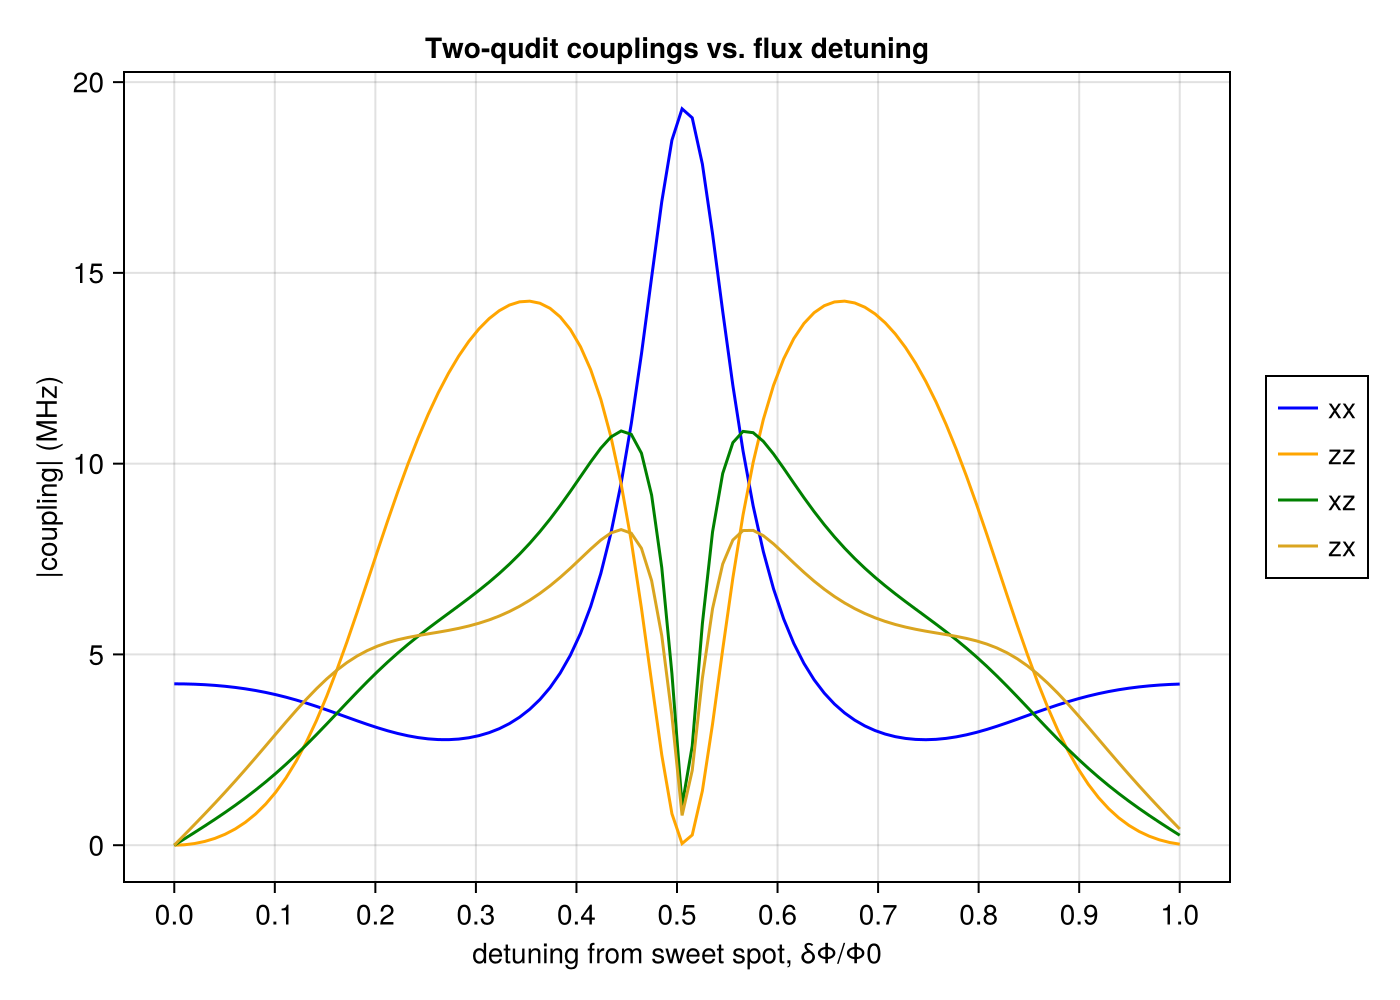

In [7]:
# sign toggles (+1 or -1): multiply the plotted curves, e.g. to undo an arbitrary eigenvector-gauge flip
xx, xz, zx = 1, 1, 1
toggles = (xx = xx, zz = 1, xz = xz, zx = zx)

fig = Figure(size = (700, 500))

ax = Axis(
    fig[1, 1];
    xlabel = "detuning from sweet spot, δΦ/Φ0",
    ylabel = "|coupling| (MHz)",
    title = "Two-qudit couplings vs. flux detuning",
    xticks = -0.0:0.1:1,
    yticks = [-10, -5, 0, 5, 10, 15, 20],
    xgridvisible = true,
    ygridvisible = true,
)

component_colors = Dict(:xx => :blue, :zz => :orange, :xz => :green, :zx => :goldenrod)

foreach((:xx, :zz, :xz, :zx)) do component
    lines!(ax, δϕs./2π, toggles[component] .* 1e3 .*  abs.(getproperty(sweep, component))./2π; label = String(component), color = component_colors[component])
end

Legend(fig[1, 2], ax)
fig

In [8]:
H_bare.fA.φ


Quantum Object:   type=Operator()   dims=[6]   size=(6, 6)   ishermitian=false
6×6 Matrix{ComplexF64}:
     -3.14159+0.0im       2.36583+0.0im  …    0.0460514+0.0im
      2.36583+0.0im      -3.14159+0.0im      9.3433e-16+0.0im
 -1.27238e-13+0.0im       1.74617+0.0im        -0.12371+0.0im
    -0.459385+0.0im  -4.49444e-14+0.0im     2.37581e-14+0.0im
 -8.35964e-16+0.0im     -0.147455+0.0im         3.53625+0.0im
    0.0460514+0.0im   8.90777e-16+0.0im  …     -3.14159+0.0im

### Pulse envelope: flat top with cosine ramps

In [9]:
function cosine_ramp_envelope(t_ramp::Real, t_plateau::Real)
    """
    Construct a flat-top pulse envelope with raised-cosine ramps.

    Returns a function `f(t)` that
      - ramps 0 → 1 on [0, t_ramp],
      - is 1 on [t_ramp, t_ramp + t_plateau],
      - ramps 1 → 0 on [t_ramp + t_plateau, 2*t_ramp + t_plateau],
      - is 0 outside [0, 2*t_ramp + t_plateau].

    Each ramp is a half-period raised cosine (Hann window): g(τ) = (1 - cos(πτ/t_ramp))/2
    for τ ∈ [0, t_ramp]. Since g'(τ) = (π/2t_ramp)*sin(πτ/t_ramp) and sin(0) = sin(π) = 0,
    the envelope has zero first derivative at every ramp/plateau/zero boundary, i.e. it is C¹.
    """
    t_down_start = t_ramp + t_plateau
    t_end = 2 * t_ramp + t_plateau

    return function(t::Real)
        if t < 0 || t > t_end
            return 0.0
        elseif t < t_ramp
            return (1 - cos(π * t / t_ramp)) / 2
        elseif t < t_down_start
            return 1.0
        else
            return (1 + cos(π * (t - t_down_start) / t_ramp)) / 2
        end
    end
end

function tanh_ramp_envelope(t_ramp::Real, t_plateau::Real; t_rise::Real=t_ramp/6)
    """
    Flat-top envelope with tanh edges, as used in Fig. 2(c) of the paper
    (characteristic rise time t_r = 2 ns there).

    Same footprint as `cosine_ramp_envelope`: total length T = 2*t_ramp + t_plateau,
    edges centered at t_ramp/2 and T - t_ramp/2 (so the half-amplitude points, and
    hence the pulse area, match the cosine envelope). Each edge is
    tanh((t - t_ramp/2)/t_rise); the default t_rise = t_ramp/6 puts the ends of each
    ramp at ±3 t_rise, i.e. 99.5% of full swing. The raw sum of the two tanh edges is
    shifted and rescaled so the envelope is exactly 0 at t = 0, T and exactly 1 at T/2,
    avoiding a small flux step at the pulse boundaries.
    """
    t_end = 2 * t_ramp + t_plateau
    t_on, t_off = t_ramp / 2, t_end - t_ramp / 2
    raw(t) = (tanh((t - t_on) / t_rise) - tanh((t - t_off) / t_rise)) / 2
    r0, r_mid = raw(0.0), raw(t_end / 2)
    return function(t::Real)
        (t < 0 || t > t_end) && return 0.0
        return (raw(t) - r0) / (r_mid - r0)
    end
end

function full_pulse(
    ω::Real,
    t_ramp::Real,
    t_plateau::Real;
    phase::Real=0.0,
    ramp_profile::Symbol=:cosine,
    t_rise::Maybe{Real}=nothing,
)
    """
    Assemble a full carrier pulse: a flat-top envelope modulating a cosine carrier.

    Returns a function `f(t) = envelope(t) * cos(ω * t + phase)`, where the envelope is
    `cosine_ramp_envelope(t_ramp, t_plateau)` for `ramp_profile = :cosine` (default) or
    `tanh_ramp_envelope(t_ramp, t_plateau; t_rise)` for `ramp_profile = :tanh`. `t_rise` is the
    tanh characteristic rise time (default t_ramp/6) and is ignored for `:cosine`.
    To match the paper's t_r = 2 ns, use `ramp_profile=:tanh, t_ramp=12.0` (or pass t_rise=2.0).

    `ω` is an angular frequency (rad per unit time), matching the convention
    used elsewhere in this notebook (EC, EL, EJ, J are all defined with an
    explicit `*2π` at their point of definition, not inside the functions
    that consume them). `phase` is in radians, default 0.
    """
    envelope = if ramp_profile === :cosine
        cosine_ramp_envelope(t_ramp, t_plateau)
    elseif ramp_profile === :tanh
        isnothing(t_rise) ? tanh_ramp_envelope(t_ramp, t_plateau) :
                            tanh_ramp_envelope(t_ramp, t_plateau; t_rise=t_rise)
    else
        throw(ArgumentError("`ramp_profile` must be :cosine or :tanh, got :$ramp_profile"))
    end
    return function(t::Real)
        return envelope(t) * cos(ω * t + phase)
    end
end


function run_spectography(
    sys::QuantumSystem,
    tlist::AbstractArray, 
    t_ramp::Real, 
    Ω_ge::Real,
    ω::Real; 
    integrator_pbar::Bool=false,
    state_tracking::Symbol=:spectrum,)
    """
    Drive subsystem A's g↔e transition with a `full_pulse`-shaped microwave
    tone at angular frequency `ω` and Rabi strength `Ω_ge`, starting from the
    symmetric superposition (|gg⟩+|ge⟩)/√2, and return the resulting
    total population that has left the initial state, 1 - |⟨ψ_0|ψ_final⟩|²,
    at the end of `tlist`.

    The pulse's plateau fills the given `tlist` window exactly: t_plateau =
    maximum(tlist) - 2*t_ramp. The drive couples through the charge operator
    `n` (standard capacitive microwave-drive coupling).

    Evolves `ψ_0` directly via `sesolve` rather than going through
    `get_propagator` -- this function only ever needs P(t_end) for a single
    fixed initial state, not the full propagator (which `get_propagator`
    computes by evolving an operator, i.e. effectively several state vectors
    at once). Verified to match the propagator-based result to machine
    precision, with a ~20x wall-clock speedup at this notebook's truncation.

    `integrator_pbar` (default false) is forwarded to `sesolve`. Leave it
    false when calling this from a sweep that already has its own progress
    bar (e.g. `figure_2a_sweep`) -- otherwise sesolve's own per-call progress
    bar dominates the output instead of the outer sweep's progress.
    """
    gg, ge, eg, ee = (state(sys, lbl; bare_to_dressed_tracking=state_tracking)[2]
    for lbl in [:gg, :ge, :eg, :ee]
    )
    ψ_0 = (1/sqrt(2)) * (gg + ge)

    # make pulse, infer t_plateu from parameters
    t_plateau = maximum(tlist) -2.5* 2 * t_ramp
    pulse = full_pulse(ω, t_ramp, t_plateau)
    H_drive = Ω_ge * sys[:fA, :n]

    # evolve the initial state directly instead of computing the full propagator
    H = QobjEvo((sys.H, (H_drive, (p, t) -> pulse(t))))
    sol = sesolve(H, ψ_0, tlist; progress_bar=Val(integrator_pbar))
    ψ_final = sol.states[end]

    # total population in fA excited state
    P = abs2(eg' * ψ_final) + abs2(ee' * ψ_final)  # population in the |eg⟩ and |ee⟩ states

    # return probability value
    return P
end

function figure_2a_sweep(
    tlist::AbstractArray, 
    t_ramp::Real, 
    ϕB_list::AbstractVector{<:Real}, 
    ω_list::AbstractVector{<:Real}, 
    Ω_ge::Real; 
    ϕA::Real=0.458 * 2π,  # TOTAL flux bias (2πΦ/Φ0), as build_H_S1 expects -- not a detuning from the sweet spot
    J::Real=J,
    integrator_pbar::Bool=false,
    state_tracking::Symbol=:spectrum,
    )
    P_transition = Matrix{Float64}(undef, length(ω_list), length(ϕB_list))
    prog = Progress(length(ϕB_list) * length(ω_list); output=stdout, showspeed=true)
    Threads.@threads for j in eachindex(ϕB_list)
        ϕB = ϕB_list[j]
        fl_mod = build_H_S1(; ϕA=ϕA, ϕB=ϕB, J=J)
        for (i, ω) in enumerate(ω_list)
            P_transition[i, j] = run_spectography(fl_mod, tlist, t_ramp, Ω_ge, ω; integrator_pbar=integrator_pbar, state_tracking=state_tracking)
            next!(prog)
        end
    end
    return P_transition
end

function calc_ζzz(sys; state_tracking=:spectrum)
    """
    Compute the residual ZZ (dispersive shift) coupling of the composite
    system's gg/ge/eg/ee energy levels:
    ζzz = |(E_ee - E_eg) - (E_ge - E_gg)| = |E_ee - E_eg - E_ge + E_gg|
    This vanishes when the joint spectrum is purely additive (no static ZZ
    interaction), i.e. when E_ee = E_eg + E_ge - E_gg.
    """
    ens = (;
        gg = state(sys, :gg; bare_to_dressed_tracking=state_tracking)[1],
        ge = state(sys, :ge; bare_to_dressed_tracking=state_tracking)[1],
        eg = state(sys, :eg; bare_to_dressed_tracking=state_tracking)[1],
        ee = state(sys, :ee; bare_to_dressed_tracking=state_tracking)[1],
    )
    ζzz = abs(
        (ens.ee + ens.gg) - (ens.ge + ens.eg)
    )
    return ζzz
end

# --- superseded by `cz_drive_op` + `cz_propagator` (which use `get_propagator`); kept for reference ---
#function get_driven_flux_ops(φA, φB, ΩA, ΩB, pulse_A, pulse_B)
#    # get direct single-qubit flux drives 
#    φA_drA, φB_drB = map((φA, φB), (ΩA, ΩB), (pulse_A, pulse_B)) do φ, Ω, pl 
#        Ωφ = Ω * φ
#        dr = (p, t) -> pl(t)
#        return QobjEvo(Ωφ, dr)
#    end
#    # get cross-talk flux drives 
#    φA_drB, φB_drA = map((φA, φB), (ΩB, ΩA), (pulse_B, pulse_A)) do φ, Ω, pl 
#        Ωφ = Ω * φ
#        dr = (p, t) -> pl(t)
#        return QobjEvo(Ωφ, dr)
#    end
#    return (φA_drA=φA_drA, φB_drB=φB_drB, φA_drB=φA_drB, φB_drA=φB_drA)
#end
#
#function get_CZ_hamiltonian(sys, tlist, t_ramp, ΩA, ΩB, ω; J=J, ramp_profile=:cosine, t_rise=nothing)
#    """
#    H(t) = H_idle + δA(t)[EL_A φA + J φB] + δB(t)[EL_B φB + J φA] (+ c-numbers),
#    which is exact for the (φ+φext)² convention of `fluxonium`. `ΩA`, `ΩB` are the
#    flux-pulse amplitudes in radians (2π δΦ/Φ0); `ω = 0` gives the square (flat-top)
#    pulses of Fig. 2(c). `ramp_profile`/`t_rise` select the envelope ramps (see `full_pulse`).
#    """
#    # assumes sys already contains static coupling term
#    t_plateu = tlist[end] - 2*t_ramp
#    pulse_A, pulse_B = [full_pulse(ω, t_ramp, t_plateu; ramp_profile=ramp_profile, t_rise=t_rise) for Ω in (ΩA, ΩB)]
#    EL_A, EL_B = sys.fA.params.EL, sys.fB.params.EL
#    φ_t = get_driven_flux_ops(sys[:fA, :φ], sys[:fB, :φ], ΩA, ΩB, pulse_A, pulse_B)
#    H_t = (
#        sys.H + # static terms
#        EL_A*φ_t.φA_drA + EL_B*φ_t.φB_drB + # time-dependent qubit flux offsets
#        J*(φ_t.φA_drB + φ_t.φB_drA) # time-dependent flux xtalk
#    )
#    return H_t
#end
#
#function run_CZ(sys, tlist, t_ramp, ΩA, ΩB, ω; J=J, abstol=1e-10, reltol=1e-10, ramp_profile=:cosine, t_rise=nothing)
#    # assumes sys already contains static coupling term (e.g. `sys_idle`)
#    gg, ge, eg, ee = (state(sys, lbl; bare_to_dressed_tracking=:overlap)[2] for lbl in [:gg, :ge, :eg, :ee])
#    I_qq = mapreduce(+, (gg, ge, eg, ee)) do ψ
#        return ψ*ψ'
#    end
#    Ht = get_CZ_hamiltonian(sys, tlist, t_ramp, ΩA, ΩB, ω; J=J, ramp_profile=ramp_profile, t_rise=t_rise)
#    Ut = sesolve(Ht, I_qq, tlist; progress_bar=Val(false), abstol=abstol, reltol=reltol).states
#    sts = (; gg, ge, eg, ee)
#    return Ut, sts
#end

function cz_drive_op(sys, ΩA, ΩB; J=J)
    """
    Flux-drive operator for the CZ pulse: with both qubits driven by the same envelope
    s(t), H(t) = H_idle + s(t) * H_int, where

        H_int = ΩA (EL_A φA + J φB) + ΩB (EL_B φB + J φA)

    is ∂H/∂δ contracted with the pulse amplitudes ΩA, ΩB (radians, 2π δΦ/Φ0). Exact for
    the (φ+φext)² convention of `fluxonium`; using φ instead of φ+π only adds a c-number
    (a global phase), which cancels in the conditional phase and in the leakage.
    Only valid when both qubits share the same envelope shape.
    """
    EL_A, EL_B = sys.fA.params.EL, sys.fB.params.EL
    φA, φB = sys[:fA, :φ], sys[:fB, :φ]
    return ΩA * (EL_A * φA + J * φB) + ΩB * (EL_B * φB + J * φA)
end

function cz_propagator(
    sys_idle,
    τ::Real,
    t_ramp::Real,
    ΩA::Real,
    ΩB::Real;
    ω::Real=0.0,
    ramp_profile::Symbol=:tanh,
    t_rise::Maybe{Real}=nothing,
    abstol::Real=1e-10,
    reltol::Real=1e-10,
    J::Real=J,
)
    """
    Computational-subspace propagator of one CZ flux pulse of total length τ (ns),
    amplitudes ΩA, ΩB (radians), carrier ω (0 for the square pulses of Fig. 2(c)) and
    envelope `full_pulse(ω, t_ramp, τ - 2t_ramp; ramp_profile, t_rise)` on both qubits.
    `sys_idle` is the idle system including the static coupling term.

    Returns (U, sts, tlist): `U` from `get_propagator` (U[end] = P U(τ) P),
    `sts = (; gg, ge, eg, ee)` the dressed idle states, and `tlist = [0, τ]`.
    """
    tlist = [0.0, τ]
    pulse = full_pulse(ω, t_ramp, τ - 2 * t_ramp; ramp_profile=ramp_profile, t_rise=t_rise)
    H_int = cz_drive_op(sys_idle, ΩA, ΩB; J=J)
    U = get_propagator(sys_idle, tlist, H_int, (p, t) -> pulse(t); abstol=abstol, reltol=reltol)
    gg, ge, eg, ee = (state(sys_idle, lbl; bare_to_dressed_tracking=:overlap)[2] for lbl in (:gg, :ge, :eg, :ee))
    return U, (; gg, ge, eg, ee), tlist
end

subspace_leakage(U) = 1 - real(tr(U' * U)) / 4   # avg. population leaving the 4-dim computational subspace

function get_νφ(Ut, sts, tlist)
    """
    Conditional phase ϕ = arg(c_ee c_gg / (c_eg c_ge)), c_k = ⟨k|U(T)|k⟩, i.e. the
    difference of qubit A's Ramsey phases with B in |e⟩ vs |g⟩ (ideal π/2 pulses).
    Single-qubit dynamic phases cancel; ϕ = -∫ζ dt with ζ = E_ee - E_eg - E_ge + E_gg.
    ϕ is only known mod 2π -- see `get_νφ_sweep` for the unwrapped version.
    Returns (ϕ [rad], ϕ/T [rad/µs], leakage 1-|c_k|² per state).
    """
    U = Ut[end]
    c = map(ψ -> ψ' * U * ψ, sts)
    ϕ = angle(c.ee * c.gg / (c.eg * c.ge))
    leak = map(x -> 1 - abs2(x), c)
    return ϕ, 1e3 * ϕ / tlist[end], leak
end

function unwrap_phase(ϕs)
    out = collect(float.(ϕs))
    for i in 2:length(out)
        out[i] = out[i-1] + rem2pi(ϕs[i] - ϕs[i-1], RoundNearest)
    end
    return out
end

function get_νφ_sweep(
    sys,
    τs,
    t_ramp,
    ΩA,
    ΩB,
    ω;
    ramp_profile::Symbol=:tanh,
    t_rise::Maybe{Real}=nothing,
    abstol::Real=1e-10,
    reltol::Real=1e-10,
    J::Real=J,
)
    """
    Run `cz_propagator` for each total pulse length τ in `τs` and unwrap ϕ(τ).
    Requires |vϕ|·step(τs) < π and |ϕ(τs[1])| < π (keep τs[1] short), and τs[1] ≥ 2 t_ramp.
    Returns (vϕ [rad/µs] = ϕ(τ_max)/τ_max as in Eq. (3), plateau slope dϕ/dτ [rad/µs],
    unwrapped ϕs, max non-adiabatic error over all τ and computational states).
    """
    res = map(τs) do τ
        U, sts, tlist = cz_propagator(sys, τ, t_ramp, ΩA, ΩB; ω=ω, ramp_profile=ramp_profile,
                                      t_rise=t_rise, abstol=abstol, reltol=reltol, J=J)
        get_νφ(U, sts, tlist)
    end
    ϕs = unwrap_phase(first.(res))
    leak = maximum(maximum(r[3]) for r in res)
    # linear fit with intercept: the ramps only add a τ-independent offset
    _, slope = hcat(ones(length(τs)), collect(τs)) \ ϕs
    return 1e3 * ϕs[end] / τs[end], 1e3 * slope, ϕs, leak
end

function static_ζ(H_bare, ΩA, ΩB; J=J)
    """
    Signed static ZZ rate ζ = E_ee - E_eg - E_ge + E_gg (rad/ns) with both qubits held
    at flux detunings ΩA, ΩB (radians, 2π δΦ/Φ0). ζ = 4 g_zz.
    """
    sys = get_perturbed_system(H_bare, ΩA, ΩB; J=J)
    E = map(l -> real(energy(sys, l; bare_to_dressed_tracking=:overlap)),
            (; gg=:gg, ge=:ge, eg=:eg, ee=:ee))
    return E.ee - E.eg - E.ge + E.gg
end

function get_νφ_point(
    sys_idle,
    H_bare,
    τ,
    t_ramp,
    ΩA,
    ΩB;
    ramp_profile::Symbol=:tanh,
    t_rise::Maybe{Real}=nothing,
    abstol::Real=1e-10,
    reltol::Real=1e-10,
    J::Real=J,
)
    """
    One Ramsey-type CZ experiment (Fig. 2(b)): flux pulses of amplitude ΩA, ΩB
    (radians) and total length τ (ns) on both qubits, square pulses (ω = 0).

    `get_νφ` only gives ϕ mod 2π, and a 200 ns pulse accumulates up to ~60 rad. The
    2π branch is chosen as the one closest to the static estimate -ζ·(pulse area),
    pulse area = τ - t_ramp for both ramp profiles. The static estimate agrees with the
    dynamics to <1% (checked at δΦ = -0.06 Φ0), far below the π needed to pick the
    wrong branch; `branch_err` (the wrapped distance to the static estimate, rad)
    flags points where that assumption fails -- treat |branch_err| ≳ π/2 as unreliable.

    Returns (vϕ [rad/µs, paper convention vϕ = 4 g_zz = -ϕ/τ], max non-adiabatic
    error over the computational states, branch_err, average leakage out of the
    computational subspace).
    """
    U, sts, tlist = cz_propagator(sys_idle, τ, t_ramp, ΩA, ΩB; ramp_profile=ramp_profile,
                                  t_rise=t_rise, abstol=abstol, reltol=reltol, J=J)
    ϕ, _, err = get_νφ(U, sts, tlist)
    ϕ_ref = -static_ζ(H_bare, ΩA, ΩB; J=J) * (τ - t_ramp)
    branch_err = rem2pi(ϕ - ϕ_ref, RoundNearest)
    ϕ_unwrapped = ϕ_ref + branch_err
    return -1e3 * ϕ_unwrapped / τ, maximum(err), branch_err, subspace_leakage(U[end])
end

function figure_2b_sweep(
    H_bare,
    δΦA_list,
    δΦB_list;
    τ::Real=200.0,
    t_ramp::Real=12.0,
    ramp_profile::Symbol=:tanh,
    t_rise::Maybe{Real}=nothing,
    abstol::Real=1e-10,
    reltol::Real=1e-10,
    J::Real=J,
)
    """
    Fig. 2(c): accumulation speed of the conditional phase, vϕ = ϕ/τ (Eq. 3, paper
    sign convention vϕ = 4 g_zz), from the dynamical CZ experiment on a grid of flux
    detunings δΦA, δΦB (units of Φ0, measured from Φ0/2). Defaults follow the paper:
    τ = 200 ns square pulses with tanh ramps of rise time t_r = t_ramp/6 = 2 ns.
    Each point uses `cz_propagator` (i.e. `get_propagator`).

    Returns (vϕ [rad/µs], max non-adiabatic error, branch_err [rad], avg. leakage),
    each indexed [i_A, j_B].
    """
    sys_idle = get_perturbed_system(H_bare, 0.0, 0.0; J=J)
    # fill the dressed-state lookup cache before threading, so threads only read it
    foreach(lbl -> state(sys_idle, lbl; bare_to_dressed_tracking=:overlap), (:gg, :ge, :eg, :ee))
    vϕ_mtrx = Matrix{Float64}(undef, length(δΦA_list), length(δΦB_list))
    err_mtrx, branch_mtrx, leak_mtrx = similar(vϕ_mtrx), similar(vϕ_mtrx), similar(vϕ_mtrx)
    pbar = Progress(length(vϕ_mtrx); output=stdout, showspeed=true)
    Threads.@threads for idx in CartesianIndices(vϕ_mtrx)
        i, j = Tuple(idx)
        vϕ_mtrx[i, j], err_mtrx[i, j], branch_mtrx[i, j], leak_mtrx[i, j] = get_νφ_point(
            sys_idle, H_bare, τ, t_ramp, 2π * δΦA_list[i], 2π * δΦB_list[j];
            ramp_profile=ramp_profile, t_rise=t_rise, abstol=abstol, reltol=reltol, J=J,
        )
        next!(pbar)
    end
    return vϕ_mtrx, err_mtrx, branch_mtrx, leak_mtrx
end

figure_2b_sweep (generic function with 1 method)

In [10]:
fig2a_sys = get_perturbed_system(H_bare, (0.458-0.5)*2π, (0.4-0.5)*2π)
λgg, λeg, λge, λee = [state(fig2a_sys, lbl; bare_to_dressed_tracking=:overlap)[1]/2π for lbl in [:gg, :eg, :ge, :ee]]
println(λee - λgg)
println(λeg - λgg)
println(λee - λge\pi)

2.458355592596897 + 0.0im
1.0398128204160093 + 0.0im
4.981715291269886 + 0.0im


In [11]:
# idle Hamiltonian (both qubits at Φ0/2) including the coupling J(φA+π)(φB+π)
# sys_idle = get_perturbed_system(H_bare, 0.0, 0.0)

# # single test point: square pulses (ω = 0), δΦA = δΦB = -0.06 Φ0
# δΦA, δΦB = -0.06, -0.06
# τs = 10.0:5.0:200.0
# vϕ, slope, ϕs, leak = get_νφ_sweep(sys_idle, τs, 2.0, 2π*δΦA, 2π*δΦB, 0.0)

# # static comparison: ζ = E_ee - E_eg - E_ge + E_gg at the plateau (expect slope ≈ -ζ)
# plat = get_perturbed_system(H_bare, 2π*δΦA, 2π*δΦB)
# E = map(l -> real(energy(plat, l; bare_to_dressed_tracking=:overlap)), (; gg=:gg, ge=:ge, eg=:eg, ee=:ee))
# ζ = E.ee - E.eg - E.ge + E.gg
# println("dynamic: vϕ = ϕ(τ)/τ = $(round(vϕ, digits=2)) rad/µs, plateau slope = $(round(slope, digits=2)) rad/µs")
# println("static:  -ζ = $(round(-1e3ζ, digits=2)) rad/µs")
# println("max leakage = $(leak)")

In [12]:
ωlist = 2π .* LinRange(1.0, 1.06, 50) 
ϕB_list = 2π .* LinRange(0.4, 0.6, 50)  # TOTAL flux bias 2πΦ_B/Φ0 (build_H_S1 convention), i.e. 0.4-0.6 Φ0

# demo placeholders for the pulse/sweep parameters figure_2a_sweep needs but
# this cell doesn't otherwise define -- tune to match the target figure
tlist = collect(LinRange(0, 100, 2))
t_ramp = 2.0
Ω_ge = 0.1

# run 2 a sweep over ranges, collect result
P_transition = figure_2a_sweep(tlist, t_ramp, ϕB_list, ωlist, Ω_ge; ϕA=0.458*2π, J=J)

# figure 2b/c sweep: dynamical CZ experiment, τ = 200 ns, tanh ramps with t_r = 2 ns (paper settings)
δΦA_list_2b = LinRange(-0.10, 0.02, 25)   # detuning from Φ0/2, units of Φ0
δΦB_list_2b = LinRange(-0.12, 0.04, 25)

# run 2 b sweep over ranges, collect result
vϕ_mtrx, err_mtrx, branch_mtrx, leak_mtrx = figure_2b_sweep(H_bare, δΦA_list_2b, δΦB_list_2b; τ=200.0, t_ramp=12.0, ramp_profile=:tanh);

Progress: 100%|███████████████████████████| Time: 0:00:18 ( 7.39 ms/it)
Progress: 100%|███████████████████████████| Time: 0:01:43 ( 0.17  s/it)


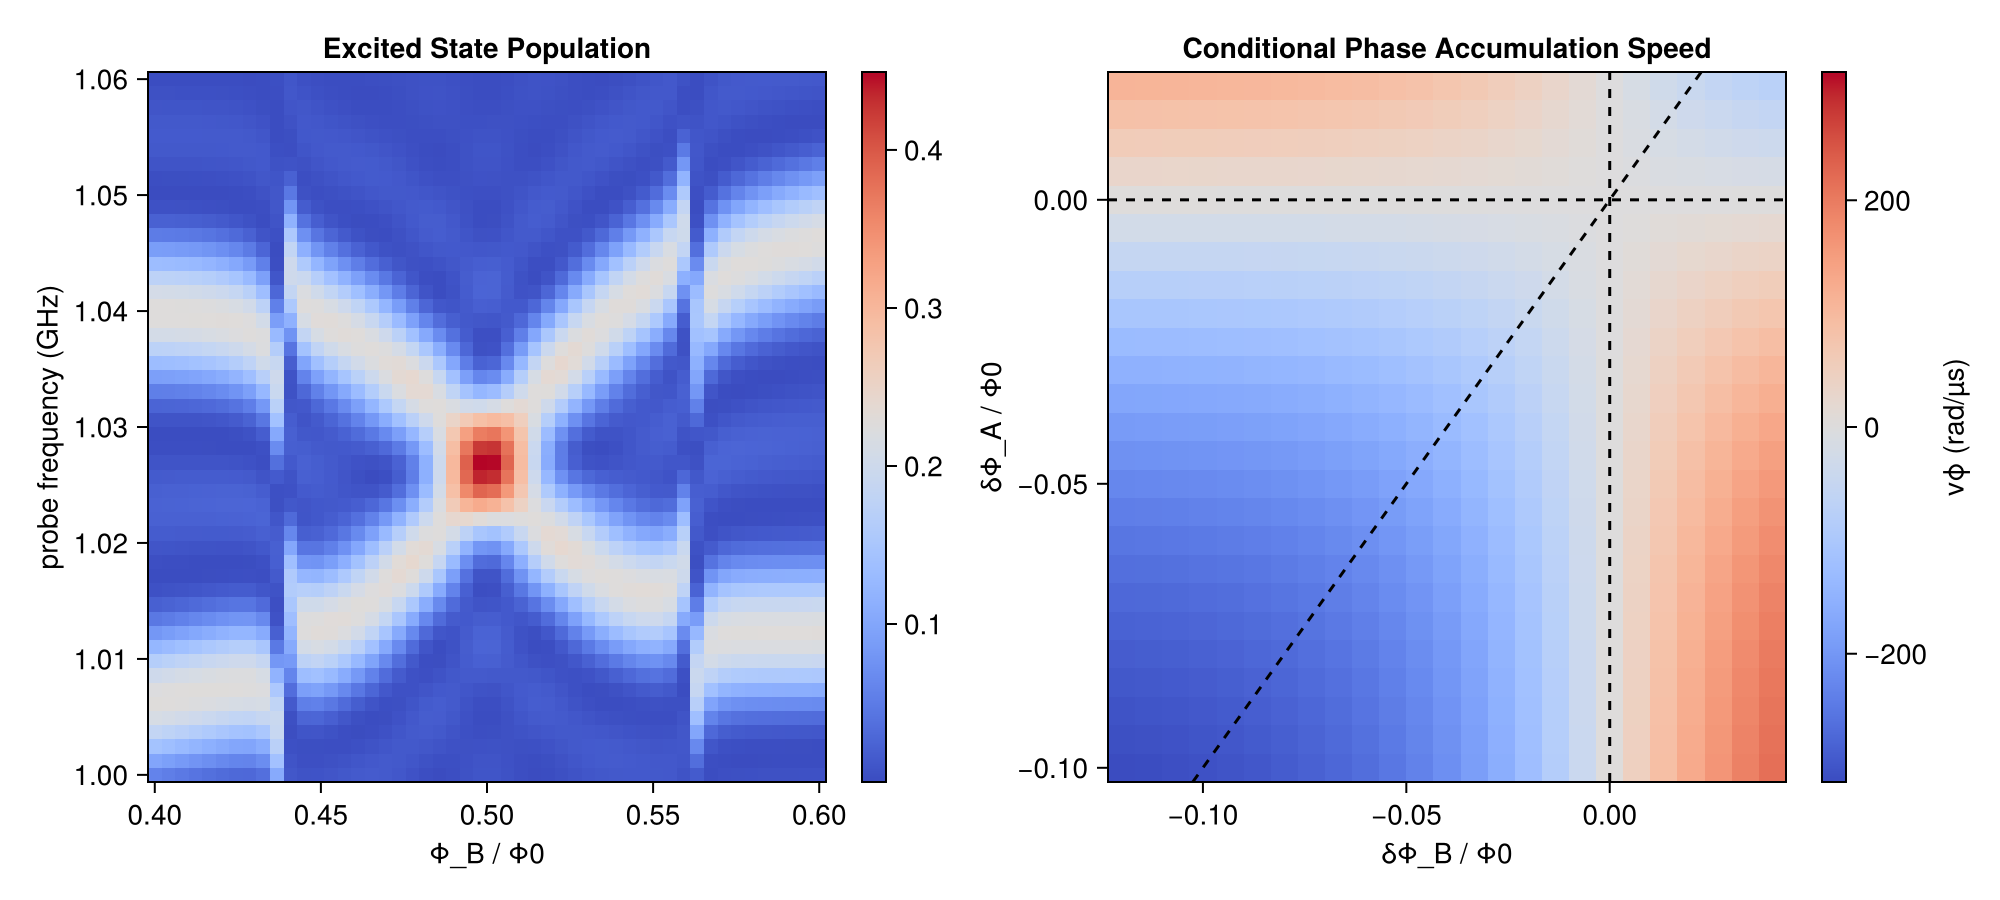

In [15]:
# plot results from above in heatmaps, side by side
# both plots go from blue for low value to red for high value 

fig = Figure(size = (1000, 450))

# fig A y-axis, probe frequency in GHz
# fig A x-axis, ϕB detuning from sweet spot
ax_a = Axis(fig[1, 1];
    xlabel = "Φ_B / Φ0",
    ylabel = "probe frequency (GHz)",
    title = "Excited State Population",
)
hm_a = heatmap!(ax_a, ϕB_list ./ 2π, ωlist ./ 2π, permutedims(P_transition); colormap = :coolwarm)
Colorbar(fig[1, 2], hm_a)

# fig C: conditional-phase accumulation speed, paper convention vϕ = 4 g_zz (blue < 0 < red)
ax_b = Axis(fig[1, 3];
    xlabel = "δΦ_B / Φ0",
    ylabel = "δΦ_A / Φ0",
    title = "Conditional Phase Accumulation Speed",
)
vmax = maximum(abs, vϕ_mtrx)
hm_b = heatmap!(ax_b, δΦB_list_2b, δΦA_list_2b, permutedims(vϕ_mtrx);
    colormap = :coolwarm, colorrange = (-vmax, vmax))
hlines!(ax_b, [0.0]; color = :black, linestyle = :dash)
vlines!(ax_b, [0.0]; color = :black, linestyle = :dash)
ablines!(ax_b, 0.0, 1.0; color = :black, linestyle = :dash)   # δΦA = δΦB
Colorbar(fig[1, 4], hm_b; label = "vϕ (rad/µs)")

fig

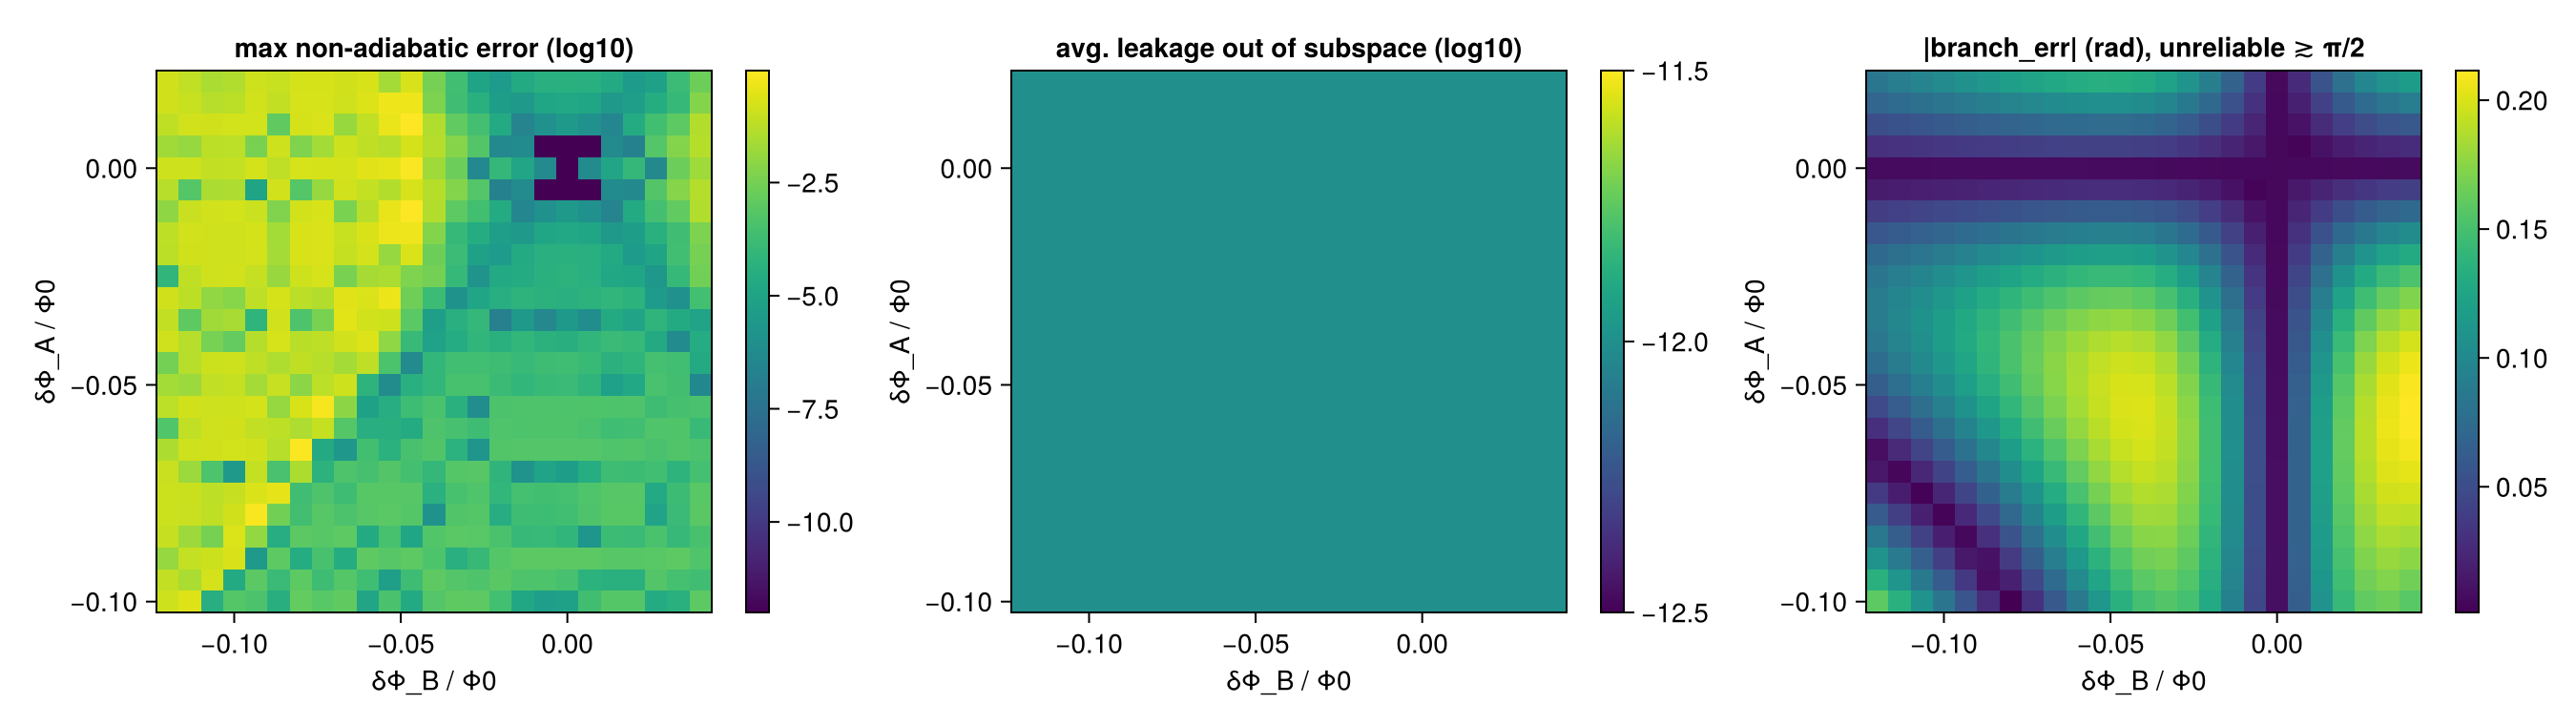

In [14]:
# diagnostics for the Fig. 2c sweep: non-adiabatic error, leakage, and 2π-branch confidence
fig_diag = Figure(size = (1350, 380))
ax_e = Axis(fig_diag[1, 1]; xlabel = "δΦ_B / Φ0", ylabel = "δΦ_A / Φ0", title = "max non-adiabatic error (log10)")
hm_e = heatmap!(ax_e, δΦB_list_2b, δΦA_list_2b, permutedims(log10.(max.(err_mtrx, 1e-12))); colormap = :viridis)
Colorbar(fig_diag[1, 2], hm_e)
ax_l = Axis(fig_diag[1, 3]; xlabel = "δΦ_B / Φ0", ylabel = "δΦ_A / Φ0", title = "avg. leakage out of subspace (log10)")
hm_l = heatmap!(ax_l, δΦB_list_2b, δΦA_list_2b, permutedims(log10.(max.(leak_mtrx, 1e-12))); colormap = :viridis)
Colorbar(fig_diag[1, 4], hm_l)
ax_r = Axis(fig_diag[1, 5]; xlabel = "δΦ_B / Φ0", ylabel = "δΦ_A / Φ0", title = "|branch_err| (rad), unreliable ≳ π/2")
hm_r = heatmap!(ax_r, δΦB_list_2b, δΦA_list_2b, permutedims(abs.(branch_mtrx)); colormap = :viridis)
Colorbar(fig_diag[1, 6], hm_r)
fig_diag